# UrbanFlow AI - Task 08 Comparative Analysis

## 1. Research question and evaluation contract

**Research question:** To what extent does the graph-enabled DCGRU improve traffic-speed forecasting compared with conventional and temporal-only approaches, and how does performance vary across horizons, sensors, and traffic conditions?

This notebook presents already-generated Task 08 summaries. It does not train models, run inference, or recalculate the bootstrap. The main result is per-horizon MAE under the finite, nonzero target mask. RMSE is complementary; the equal-horizon mean is secondary.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if not (root / 'results' / 'task08_comparison').is_dir():
    root = root.parent
result_dir = root / 'results' / 'task08_comparison'
figure_dir = result_dir / 'figures'
assert result_dir.is_dir(), 'Run scripts/run_comparative_analysis.py from the repository root first.'
overall = json.loads((result_dir / 'overall_metrics.json').read_text(encoding='utf-8'))
bootstrap = json.loads((result_dir / 'bootstrap_summary.json').read_text(encoding='utf-8'))
metrics = pd.DataFrame(overall['metrics'])
pairwise = pd.read_csv(result_dir / 'pairwise_differences.csv')
sensors = pd.read_csv(result_dir / 'sensor_metrics.csv')
strata = pd.read_csv(result_dir / 'observed_speed_strata.csv')
temporal = pd.read_csv(result_dir / 'temporal_metrics.csv')
print('Loaded generated Task 08 summaries from', result_dir)

Loaded generated Task 08 summaries from results/task08_comparison


## 2. Artifact integrity and dataset alignment

The generator accepts results only after checking artifact SHA-256 values, shape `(6844, 3, 207)`, target values, forecast origins, target timestamps, sensor order, horizons, masks, dataset identity, and split boundaries. The table below exposes that provenance for review.

In [2]:
pd.DataFrame({
    'property': ['shape', 'horizons', 'primary policy', 'sensitivity policy', 'data SHA-256'],
    'value': [overall['shape'], overall['primary_finding_contract']['horizons_minutes'],
              overall['primary_finding_contract']['mask_policy'], overall['sensitivity_policy'],
              overall['data_sha256']]
})

,property,value
0,shape,"[6844, 3, 207]"
1,horizons,"[15, 30, 60]"
2,primary policy,finite_nonzero_targets
3,sensitivity policy,all_finite_targets_including_zeros
4,data SHA-256,8D67A35472DB1719D7D4BE851F2BF64CB21D9C52577C8A...


## 3. Primary MAE/RMSE comparison

Primary metrics exclude finite exact-zero targets because their meaning is unresolved. Values remain in original traffic-speed units (mph). A lower value is better.

mae_mph                 rmse_mph                  
horizon_minutes         15      30      60       15       30       60
model_label                                                          
DCGRU-64            2.9748  3.2627  3.9621   5.7350   6.4829   8.0355
GRU-128             2.9618  3.3907  4.1336   5.8154   6.9243   8.5397
Historical Average  7.1104  7.1104  7.1108   9.8311   9.8311   9.8313
Persistence         4.0175  5.0952  6.7980   8.6955  11.1353  14.2136
XGBoost             3.0044  3.5235  4.0866   5.4669   6.4889   7.4888

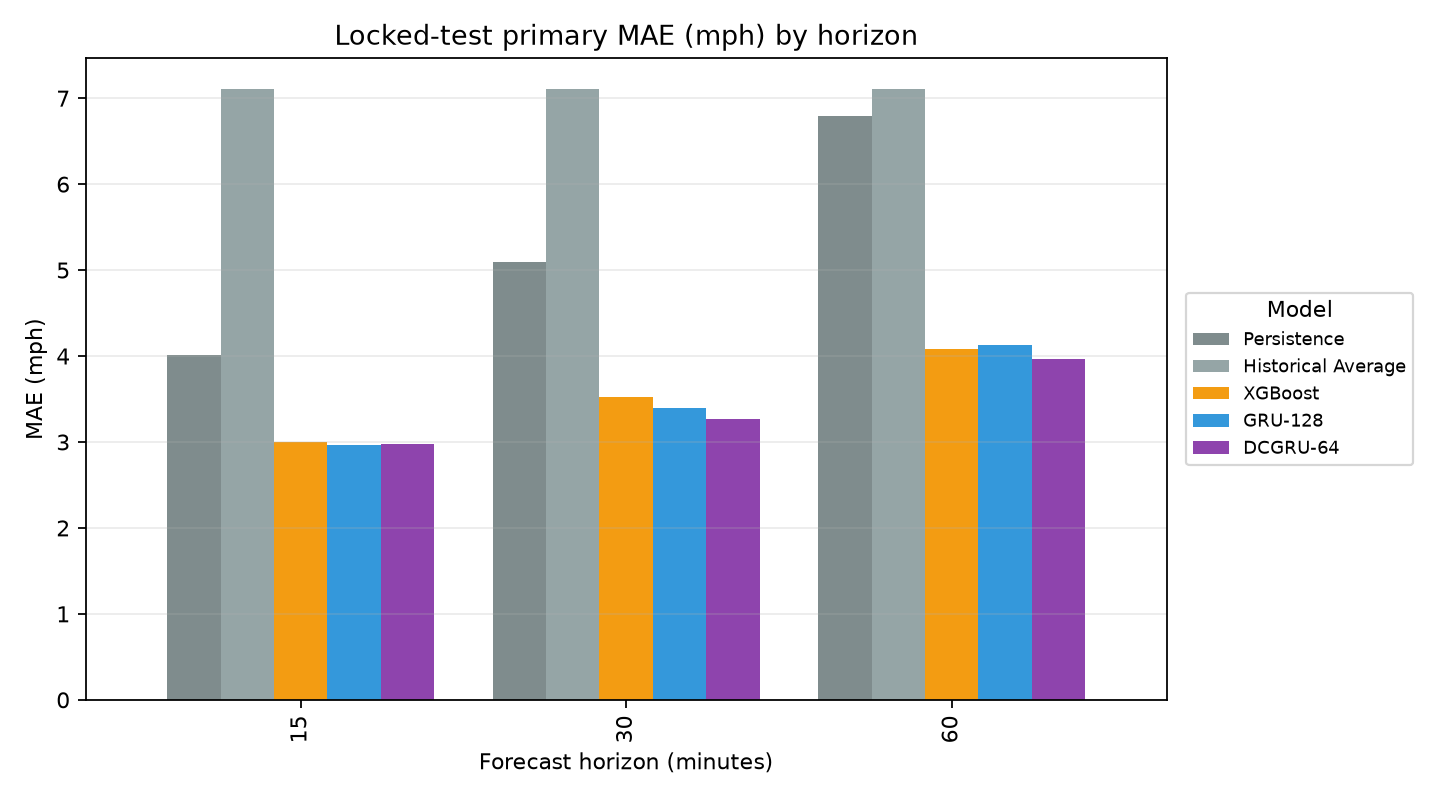

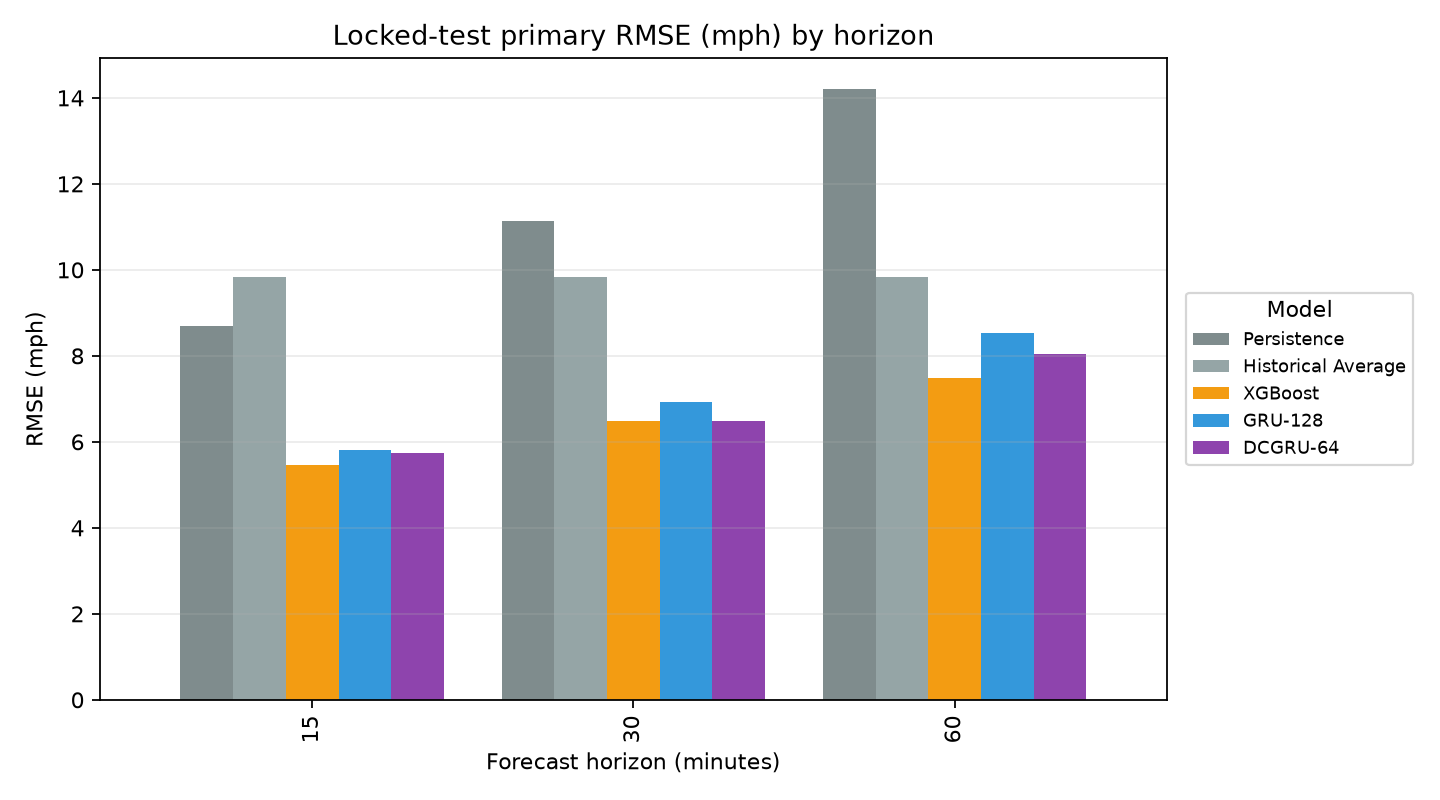

In [3]:
primary = metrics[metrics['mask_policy'] == 'finite_nonzero_targets']
primary_table = primary.pivot(index='model_label', columns='horizon_minutes', values=['mae_mph', 'rmse_mph'])
display(primary_table.round(4))
display(Image(filename=str(figure_dir / 'primary_mae_by_horizon.png')))
display(Image(filename=str(figure_dir / 'primary_rmse_by_horizon.png')))

## 4. Per-horizon findings and pairwise improvements

Positive improvement percentages mean DCGRU reduced MAE relative to the comparator. The result is mixed: GRU is slightly better at +15 minutes, while DCGRU is better at +30 and +60 minutes.

,horizon_minutes,comparator_label,dcgru_minus_comparator_mae_mph,improvement_percent
0,15,GRU-128,0.0130,-0.4402
1,15,XGBoost,-0.0295,0.9830
2,15,Persistence,-1.0427,25.9535
3,15,Historical Average,-4.1355,58.1617
4,30,GRU-128,-0.1280,3.7743
5,30,XGBoost,-0.2608,7.4006
6,30,Persistence,-1.8325,35.9649
7,30,Historical Average,-3.8477,54.1131
8,60,GRU-128,-0.1715,4.1499
9,60,XGBoost,-0.1245,3.0468


,horizon_minutes,metric,model,model_label,value_mph
0,15,mae_mph,gru,GRU-128,2.9618
1,15,rmse_mph,xgboost,XGBoost,5.4669
2,30,mae_mph,dcrnn,DCGRU-64,3.2627
3,30,rmse_mph,dcrnn,DCGRU-64,6.4829
4,60,mae_mph,dcrnn,DCGRU-64,3.9621
5,60,rmse_mph,xgboost,XGBoost,7.4888


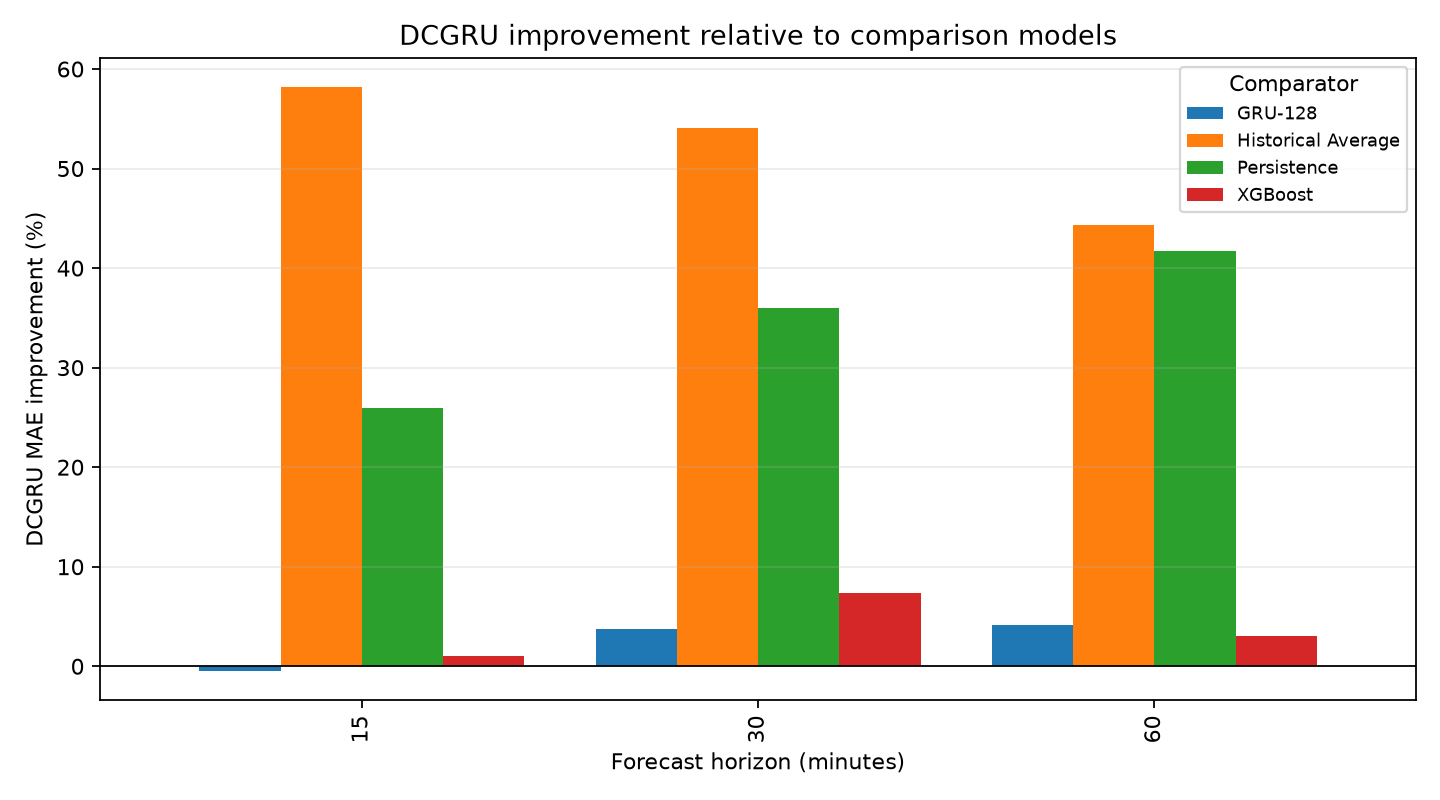

In [4]:
primary_pairs = pairwise[(pairwise['mask_policy'] == 'finite_nonzero_targets') & (pairwise['summary'] == 'per_horizon')]
display(primary_pairs[['horizon_minutes', 'comparator_label', 'dcgru_minus_comparator_mae_mph', 'improvement_percent']].round(4))
display(pd.DataFrame(overall['best_primary_models']).round(4))
display(Image(filename=str(figure_dir / 'dcgru_pairwise_improvement.png')))

## 5. Secondary equal-horizon summary

This is an equal-weight average of the three horizon MAEs. It is useful as a compact summary but does not replace the primary horizon-specific findings.

,model,model_label,mask_policy,equal_horizon_mean_mae_mph
8,dcrnn,DCGRU-64,finite_nonzero_targets,3.3999
6,gru,GRU-128,finite_nonzero_targets,3.4954
4,xgboost,XGBoost,finite_nonzero_targets,3.5382
0,persistence,Persistence,finite_nonzero_targets,5.3036
2,historical_average,Historical Average,finite_nonzero_targets,7.1105


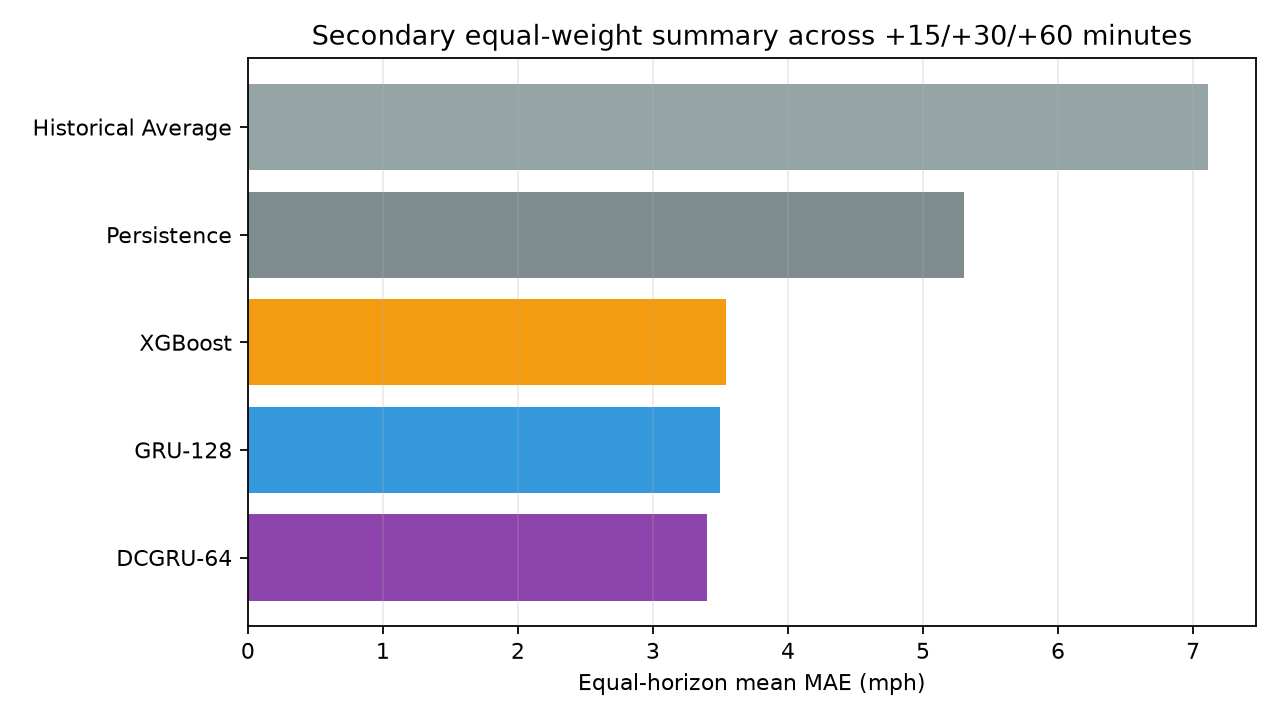

In [5]:
means = pd.DataFrame(overall['equal_horizon_mean_mae'])
display(means[means['mask_policy'] == 'finite_nonzero_targets'].sort_values('equal_horizon_mean_mae_mph').round(4))
display(Image(filename=str(figure_dir / 'primary_equal_horizon_mean_mae.png')))

## 6. Sensor-level error analysis

All 207 sensors are included. Negative DCGRU-minus-GRU differences favor DCGRU. The sorted curves show the complete distribution instead of selecting only favorable examples. Sensor-specific findings are exploratory and may not generalize beyond this test period.

,horizon_minutes,valid_sensor_count,improved_sensor_count,improved_sensor_percent,median_dcgru_minus_gru_mae_mph,median_improvement_percent,best_sensor_id,best_dcgru_minus_gru_mae_mph,worst_sensor_id,worst_dcgru_minus_gru_mae_mph
0,15,207,99,47.8261,0.0048,-0.2566,764858,-0.4298,773012,0.9516
1,30,207,166,80.1932,-0.0789,2.5337,773939,-0.6909,773012,0.6915
2,60,207,157,75.8454,-0.0809,2.4542,773939,-1.0891,773012,0.5884


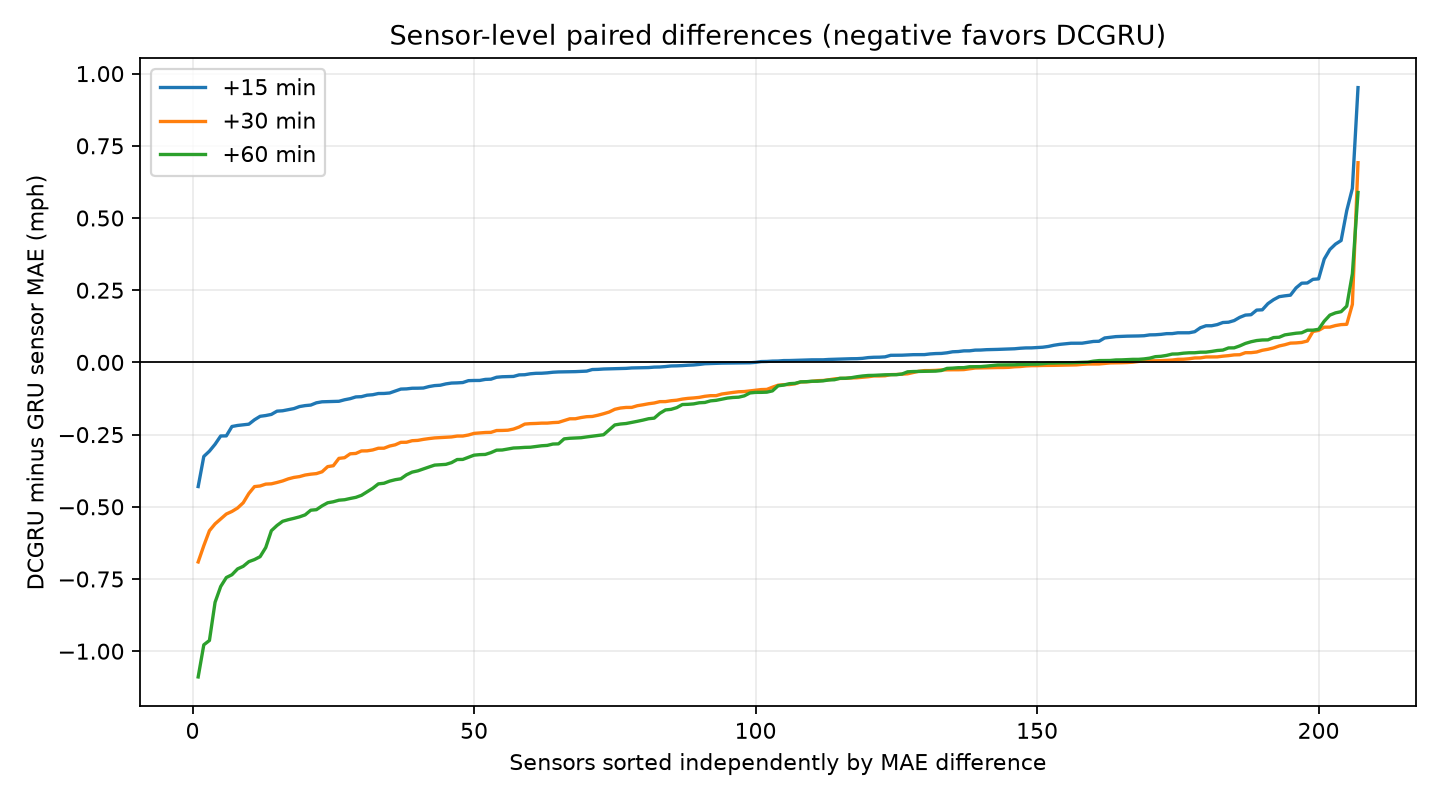

In [6]:
sensor_summary = pd.DataFrame(overall['sensor_dcgru_vs_gru_summary'])
display(sensor_summary.round(4))
display(Image(filename=str(figure_dir / 'sensor_dcgru_minus_gru.png')))

## 7. Observed-Speed Evaluation Strata

The fixed bands are Low `<20 mph`, Medium `20 to <40 mph`, and High `>=40 mph`. They use the observed future target and are available only for retrospective evaluation, not when a forecast is made. At +15 minutes, the primary evaluation contains 41,992 low-speed observations (3.37%), 111,730 medium-speed observations (8.97%), and 1,091,318 high-speed observations (87.65%); the proportions are nearly identical at +30 and +60 minutes. The bands are therefore not equally represented, and pooled results are not equally representative of every sensor. The table below reports the exact eligible count and percentage for every horizon.

,horizon_minutes,speed_band,eligible_count,eligible_percent
4,15,low_below_20,41992,3.3727
9,15,medium_20_to_below_40,111730,8.9740
14,15,high_40_and_above,1091318,87.6532
19,30,low_below_20,41992,3.3728
24,30,medium_20_to_below_40,111724,8.9737
29,30,high_40_and_above,1091306,87.6536
34,60,low_below_20,41992,3.3729
39,60,medium_20_to_below_40,111716,8.9733
44,60,high_40_and_above,1091278,87.6538


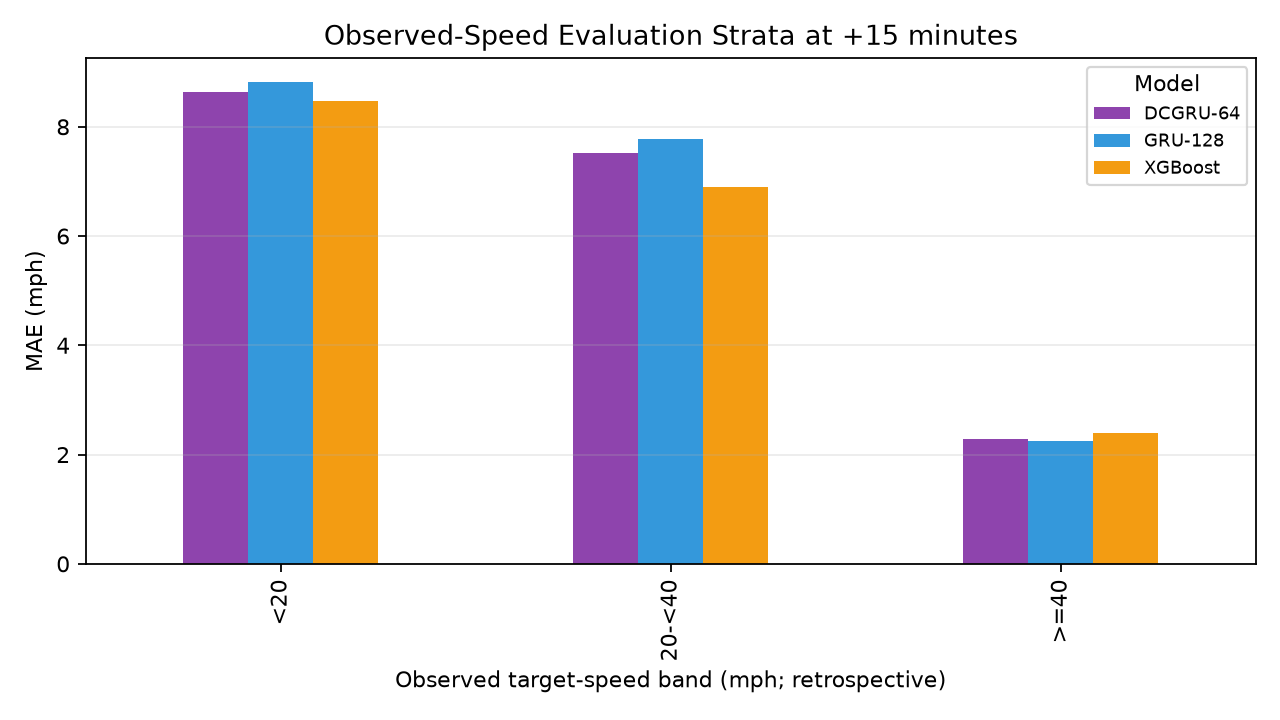

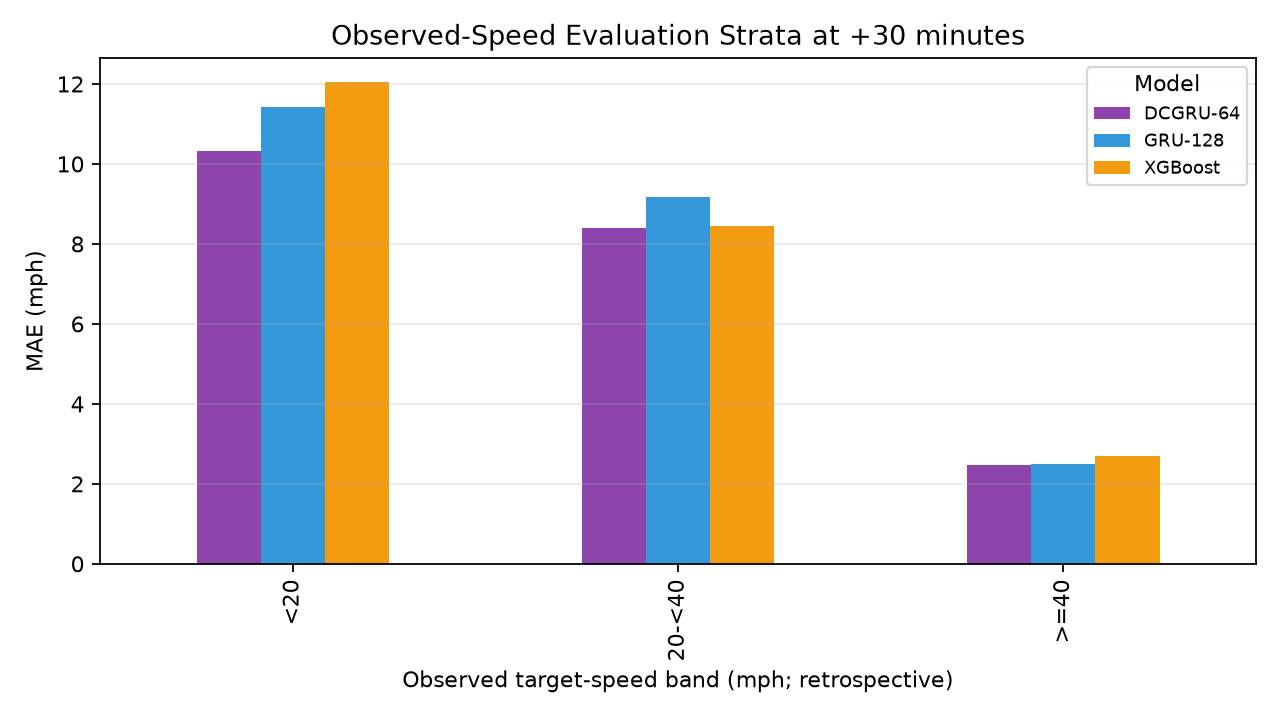

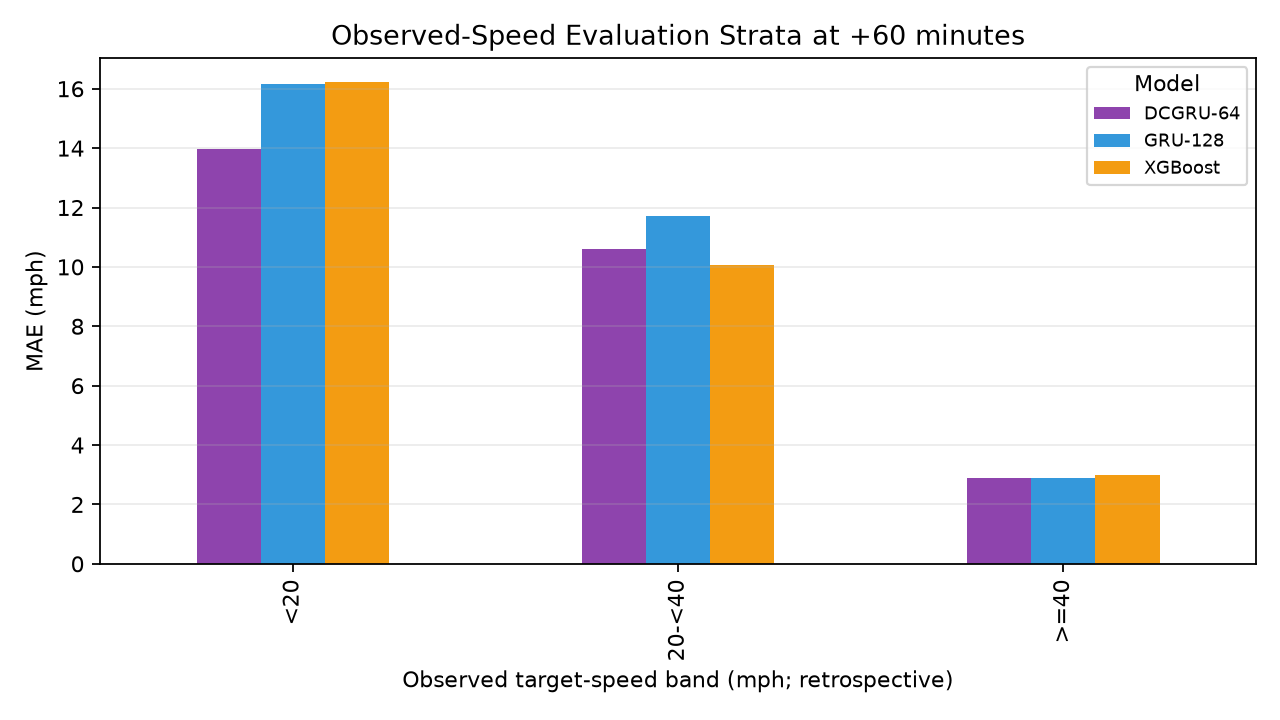

In [7]:
primary_strata = strata[strata['mask_policy'] == 'finite_nonzero_targets']
counts = primary_strata[primary_strata['model'] == 'dcrnn'][['horizon_minutes', 'speed_band', 'eligible_count', 'eligible_percent']]
display(counts.round(4))
for horizon in (15, 30, 60):
    display(Image(filename=str(figure_dir / f'observed_speed_strata_h{horizon}.png')))

## 8. Temporal performance analysis

Time-of-day groups are predefined as 00:00-<06:00, 06:00-<12:00, 12:00-<18:00, and 18:00-<24:00. Weekday/weekend and target-date breakdowns use timezone-naive stored target timestamps. Partial boundary days are retained. These findings are exploratory.

,group_type,group,mask_policy,model,model_label,horizon_minutes,eligible_count,mae_mph,rmse_mph
3,time_of_day,overnight_00_06,finite_nonzero_targets,gru,GRU-128,15,288309,2.4460,3.6353
4,time_of_day,overnight_00_06,finite_nonzero_targets,dcrnn,DCGRU-64,15,288309,2.4867,3.7034
8,time_of_day,morning_06_12,finite_nonzero_targets,gru,GRU-128,15,301556,3.0071,6.2229
9,time_of_day,morning_06_12,finite_nonzero_targets,dcrnn,DCGRU-64,15,301556,3.0818,6.2500
13,time_of_day,afternoon_12_18,finite_nonzero_targets,gru,GRU-128,15,324461,3.5892,7.0091
14,time_of_day,afternoon_12_18,finite_nonzero_targets,dcrnn,DCGRU-64,15,324461,3.5789,6.7625
18,time_of_day,evening_18_24,finite_nonzero_targets,gru,GRU-128,15,330714,2.7547,5.6822
19,time_of_day,evening_18_24,finite_nonzero_targets,dcrnn,DCGRU-64,15,330714,2.7102,5.6017
303,time_of_day,overnight_00_06,finite_nonzero_targets,gru,GRU-128,30,287691,2.5033,3.7572
304,time_of_day,overnight_00_06,finite_nonzero_targets,dcrnn,DCGRU-64,30,287691,2.5134,3.7646


,group_type,group,mask_policy,model,model_label,horizon_minutes,eligible_count,mae_mph,rmse_mph
23,day_type,weekday,finite_nonzero_targets,gru,GRU-128,15,990682,3.0806,5.9518
24,day_type,weekday,finite_nonzero_targets,dcrnn,DCGRU-64,15,990682,3.1142,5.8991
28,day_type,weekend,finite_nonzero_targets,gru,GRU-128,15,254358,2.4991,5.2502
29,day_type,weekend,finite_nonzero_targets,dcrnn,DCGRU-64,15,254358,2.4319,5.0449
323,day_type,weekday,finite_nonzero_targets,gru,GRU-128,30,990664,3.5387,7.1140
324,day_type,weekday,finite_nonzero_targets,dcrnn,DCGRU-64,30,990664,3.4073,6.6501
328,day_type,weekend,finite_nonzero_targets,gru,GRU-128,30,254358,2.8142,6.1298
329,day_type,weekend,finite_nonzero_targets,dcrnn,DCGRU-64,30,254358,2.6997,5.7857
623,day_type,weekday,finite_nonzero_targets,gru,GRU-128,60,990628,4.3469,8.8378
624,day_type,weekday,finite_nonzero_targets,dcrnn,DCGRU-64,60,990628,4.1698,8.3064


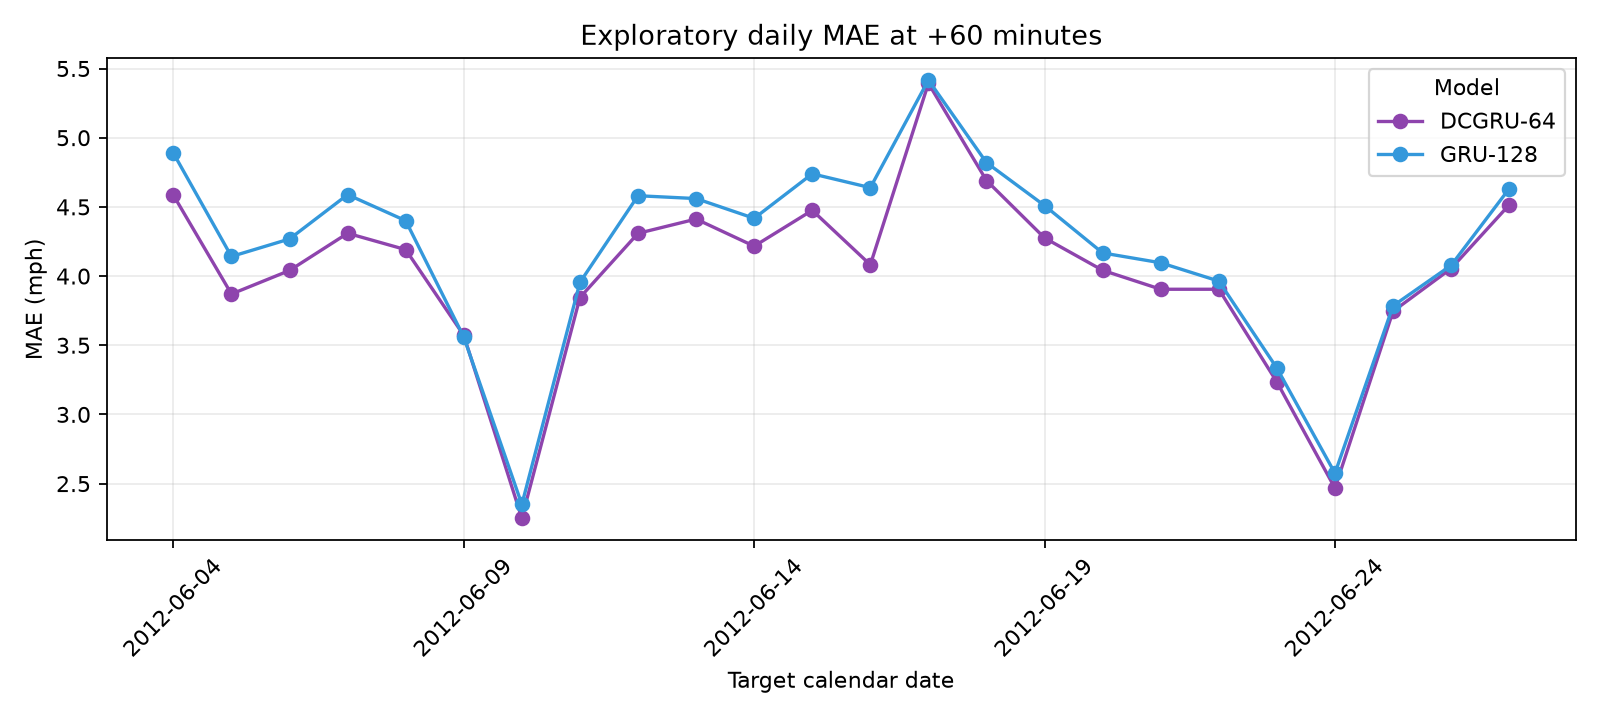

In [8]:
temporal_focus = temporal[(temporal['mask_policy'] == 'finite_nonzero_targets') & temporal['model'].isin(['gru', 'dcrnn'])]
display(temporal_focus[temporal_focus['group_type'] == 'time_of_day'].round(4))
display(temporal_focus[temporal_focus['group_type'] == 'day_type'].round(4))
display(Image(filename=str(figure_dir / 'daily_gru_dcgru_h60.png')))

## 9. Paired bootstrap uncertainty intervals

The exploratory paired day-cluster bootstrap resamples 24 target calendar dates with replacement. It uses 10,000 repetitions, seed 268513, and count-weighted pooled MAE. Negative differences favor DCGRU. These intervals describe stability under day resampling; they are not formal significance tests or causal evidence.

In [9]:
bootstrap_rows = []
for item in bootstrap['comparisons']:
    for row in item['rows']:
        bootstrap_rows.append({'comparator': item['comparator_label'], **row})
display(pd.DataFrame(bootstrap_rows).round(4))
pd.DataFrame({'limitation': bootstrap['limitations']})

,comparator,horizon_minutes,dcgru_minus_comparator_mae_mph,interval_95_low_mph,interval_95_high_mph
0,GRU-128,15,0.0130,-0.0155,0.0399
1,GRU-128,30,-0.1280,-0.1605,-0.0970
2,GRU-128,60,-0.1715,-0.2131,-0.1316
3,XGBoost,15,-0.0295,-0.0801,0.0127
4,XGBoost,30,-0.2608,-0.3264,-0.2061
5,XGBoost,60,-0.1245,-0.2883,0.0115


,limitation
0,Only 24 target-date clusters are available.
1,Forecast windows overlap and adjacent errors a...
2,Input history can be shared across midnight an...
3,The locked test period is limited to 4-27 June...
4,The bootstrap was proposed after the primary l...
5,Intervals are exploratory and do not establish...


## 10. Exact-zero sensitivity analysis

The sensitivity policy includes all finite exact-zero targets. These readings substantially worsen learned-model errors and may reflect unresolved missingness or data-quality semantics. They are not assumed to be confirmed physical standstills. Sensitivity results remain separate from the primary headline.

In [10]:
sensitivity = metrics[metrics['mask_policy'] == 'all_finite_targets_including_zeros']
display(pd.DataFrame([overall['exact_zero_counts_by_horizon']], index=['exact-zero count']))
display(sensitivity.pivot(index='model_label', columns='horizon_minutes', values=['mae_mph', 'rmse_mph']).round(4))

,15,30,60
exact-zero count,171668,171686,171722


mae_mph                   rmse_mph                  
horizon_minutes          15       30       60       15       30       60
model_label                                                             
DCGRU-64             9.8819  10.1274  10.7362  21.7903  21.9597  22.3988
GRU-128              9.6913  10.0632  10.7158  21.3552  21.6372  22.1458
Historical Average  12.9528  12.9534  12.9551  21.6593  21.6603  21.6624
Persistence          4.0564   5.3787   7.4254   9.9299  12.8079  16.3345
XGBoost              9.5093   9.9989  10.5082  20.7035  21.0911  21.4319

## 11. Direct answer to the research question

The graph-enabled DCGRU achieved a **modest, horizon-dependent predictive advantage** over the closely sized temporal-only GRU. It performed slightly worse at +15 minutes, but reduced MAE at +30 and +60 minutes and had the best secondary equal-horizon mean MAE. This pattern is consistent with spatial relationships becoming more useful at longer horizons, but the experiment does not isolate graph structure as the causal source because the architectures are not identical and no identity-only ablation was approved.

## 12. Scientific limitations and reproducibility

- METR-LA covers one historical Los Angeles sensor network and a limited test period.
- Exact-zero semantics remain unresolved and materially affect metrics.
- Sensor, speed-stratum, temporal, and bootstrap analyses are exploratory.
- The bootstrap has only 24 day clusters and overlapping forecast windows.
- Predictive improvements do not demonstrate causality.
- The results are regenerated with `python scripts/run_comparative_analysis.py`; source artifact hashes and configuration are recorded in the JSON outputs.